# Mini-Thesis: Synthetic Test Corpus & Evidence-Recovery Measurement
## Anti-Forensic Techniques in Encrypted Mobile Applications: Case Study of WhatsApp and Telegram

**Researcher:** Gerhard Uundjondjo (226111989) &nbsp;|&nbsp; **Supervisor:** Mr. Isaac Nhamu
&nbsp;|&nbsp; Department of Cyber Security, NUST

**Purpose.** This notebook produces the *synthetic dataset* described in Chapter 3 (Section 3.2.4) and the
tooling used to measure evidence recovery for Chapter 4. It is adapted from the SAS821S end-to-end template:
the template's *pipeline shape* (setup → synthetic data generation → data engineering → exploratory
description → analysis → saved outputs) is kept, but the *content* is replaced to fit a controlled
mobile-forensics experiment rather than a SOC analytics scenario.

| Section | Purpose | Thesis link |
|---|---|---|
| 0. Setup & lab configuration | Folders, seed, device/modality settings | 3.2.5 Tools and Instruments |
| 1. Experimental design | Conditions (anti-forensic mechanisms) and acquisition plan | 3.2.1 Research Design |
| 2. Test accounts | Controlled synthetic test identities | 3.2.6 Ethical Considerations |
| 3. Marker tokens | Unique, searchable ground-truth tokens per item | 3.2.4 Data Collection |
| 4. Text corpus | Synthetic chat messages | 3.2.2 Target Population |
| 5. Media corpus | Images (with EXIF/GPS), documents, voice-note scripts | 3.2.4 Data Collection |
| 6. Ground-truth manifest | One row per seeded item, with hashes | 3.2.4 Data Collection |
| 7. Data engineering & QC | Data dictionary, provenance log, quality checks | 3.2.4 Data Collection |
| 8. Corpus description | Composition table and chart | Table/Figure for Chapter 3 |
| 9. Seeding run sheets | Step-by-step device execution protocol | 3.2.4 Data Collection |
| 10. Recovery measurement | Marker scanner, image matcher, EXIF check, recovery rates | Chapter 4 |
| 11. Pipeline self-test | Validates the measurement tooling (not results) | 3.2.7 Limitations |

**How the experiment works.** Every seeded item carries a unique *marker token* (for example
`AFXW0042K7Q`). After seeding the test device and applying each anti-forensic action, the device is acquired
using each modality. The measurement tools then search every acquisition for the markers (in UTF-8 and
UTF-16LE), match recovered images by perceptual hash and documents by SHA-256, and compute recovery rates by
condition, modality and time point against the ground-truth manifest.

> **Integrity note.** All message content is synthetic and generated in code; all accounts are dedicated test
> accounts. This notebook does **not** simulate recovery outcomes. Recovery results come only from real
> acquisitions placed in `03_acquisitions/`.

## 0. Setup and lab configuration

In [1]:
import os, re, json, random, hashlib, base64, datetime, shutil, math, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont

SEED = 226111989                      # reproducible corpus (student number as seed)
RNG = np.random.default_rng(SEED)
random.seed(SEED)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

BASE_DIR = "UUNDJONDJO_226111989_AntiForensics_Corpus"
FOLDERS = {
    "design":       "01_design",
    "manifest":     "02_corpus/manifest",
    "images":       "02_corpus/media/images",
    "documents":    "02_corpus/media/documents",
    "voice":        "02_corpus/media/voice_scripts",
    "runsheets":    "02_corpus/run_sheets",
    "acquisitions": "03_acquisitions",
    "analysis":     "04_analysis",
    "outputs":      "05_outputs",
    "docs":         "06_documentation",
}
P = {k: os.path.join(BASE_DIR, v) for k, v in FOLDERS.items()}
for p in P.values():
    os.makedirs(p, exist_ok=True)
print("Working folders ready under:", BASE_DIR)

Working folders ready under: UUNDJONDJO_226111989_AntiForensics_Corpus


### 0.1 Lab configuration — confirmed against the real device

`DEVICES` records the single device under examination, confirmed on 23 September 2026 via `adb`
(`getprop`/`dumpsys`, run over USB from a Windows machine). Root status was checked directly with
`adb shell su -c id`, which returned `su: inaccessible or not found` — the device is **not rooted**, and
this is a confirmed result, not an assumption. Add a second dictionary to `DEVICES` only if a second
physical device becomes available; do not add placeholder devices.

Because the device is not rooted, three of the four originally planned modalities (file-system extraction,
physical imaging, LiME memory capture) all require root and are unavailable. Only logical ADB acquisition
is used. Neither WhatsApp nor Telegram is a debuggable build and neither supports `adb backup` on current
Android, so app private storage (`msgstore.db`, `cache4.db`) is expected to be unreachable; the acquisition
instead targets the externally-writable media folders each app uses for photos, videos and voice notes.
That expected inaccessibility of app-private data without root is itself recorded as a result relevant to
Objective 3 (tool/investigator effectiveness), not treated as a gap in the method.

Timers must be **longer** than the time needed to complete all T0 acquisitions, otherwise the "before
expiry" state cannot be captured.

In [ ]:
DEVICES = [
    {"device_id": "DEV01", "model": "Samsung SM-A245F (Galaxy A24)", "android_version": "16",
     "security_patch": "2026-07-05",
     "rooted": "No (confirmed: adb shell su -c id -> 'su: inaccessible or not found', 23 Sep 2026)",
     "whatsapp_version": "2.26.40.76 during the WhatsApp run (19-20 Oct 2026); 2.26.36.74 at the 23 Sep check",
     "telegram_version": "13.0.3 during Telegram run 2 (21-22 Oct 2026); 12.10.3 at run-1 T0 (9 Oct), auto-updated 17 Oct",
     "role": "device under examination (holds test accounts A)"},
]
PEER_DEVICE = {"device_id": "PEER", "role": "peer device (holds test accounts B); never acquired"}

# Acquisition modalities (Chapter 3). DEV01 is not rooted, so only logical ADB acquisition is available;
# file_system/physical_image/memory_lime are left here, commented out, as the modalities the design
# would use on a rooted device, for transparency about what the confirmed root status ruled out.
MODALITIES = {
    "logical_adb": "ADB acquisition: (a) pull of externally-writable app media folders "
                    "(/sdcard/Android/media/com.whatsapp, /sdcard/Android/media/org.telegram.messenger) "
                    "and (b) an attempted adb backup of both applications, expected to fail on current "
                    "Android and recorded as such if it does",
    # "file_system":    "Full file-system extraction of app private storage (requires root) -- UNAVAILABLE: DEV01 not rooted",
    # "physical_image": "Bit-for-bit image of the userdata partition (requires root) -- UNAVAILABLE: DEV01 not rooted",
    # "memory_lime":    "Volatile memory capture with LiME (requires root) -- UNAVAILABLE: DEV01 not rooted",
}

# Acquisition time points
TIMEPOINTS = {
    "T0": "Immediately after seeding, before any deletion action or timer expiry",
    "T1": "After deletion actions performed and all timers expired",
}

# Items seeded per condition (per allowed message type)
PER_CONDITION = {"text": 20, "image": 4, "document": 2, "voice_note": 2}

# Timer parameters (edit if you choose different settings in the apps)
WA_DISAPPEARING_TIMER = "24 hours"
TG_AUTODELETE_TIMER   = "1 day"
TG_SECRET_SD_TIMER    = "1 hour"

pd.DataFrame(DEVICES)

## 1. Experimental design — conditions and acquisition plan

Each **condition** isolates one anti-forensic mechanism on one platform (Objective 1). Baseline conditions
(no anti-forensic action) act as controls: comparing a mechanism's recovery rate to its platform baseline
isolates the mechanism's effect (Objectives 2 and 3).

All conditions are seeded on the same device in separate chats, so a single acquisition captures every
condition at once; conditions are separated afterwards by their marker tokens. The acquisition plan is
therefore *device × modality × time point*.

In [3]:
ALL_TYPES = ["text", "image", "document", "voice_note"]

conditions = pd.DataFrame([
    # id,               platform,   chat_mode,      mechanism,               action,                 parameter,              allowed types
    ("WA_BASE",         "WhatsApp", "standard_e2ee", "none (control)",        "none",                 "",                     ALL_TYPES),
    ("WA_DISAPPEAR",    "WhatsApp", "standard_e2ee", "ephemeral_messaging",   "enable_disappearing",  WA_DISAPPEARING_TIMER,  ALL_TYPES),
    ("WA_DEL_ALL",      "WhatsApp", "standard_e2ee", "secure_deletion",       "delete_for_everyone",  "",                     ALL_TYPES),
    ("WA_DEL_ME",       "WhatsApp", "standard_e2ee", "secure_deletion",       "delete_for_me",        "",                     ALL_TYPES),
    ("WA_VIEW_ONCE",    "WhatsApp", "standard_e2ee", "ephemeral_media",       "view_once",            "",                     ["image", "voice_note"]),
    ("TG_CLOUD_BASE",   "Telegram", "cloud_chat",    "none (control)",        "none",                 "",                     ALL_TYPES),
    ("TG_CLOUD_DEL",    "Telegram", "cloud_chat",    "secure_deletion",       "delete_for_both",      "",                     ALL_TYPES),
    ("TG_CLOUD_AUTODEL","Telegram", "cloud_chat",    "ephemeral_messaging",   "enable_auto_delete",   TG_AUTODELETE_TIMER,    ALL_TYPES),
    ("TG_SECRET_BASE",  "Telegram", "secret_chat",   "e2ee_secret_chat",      "none",                 "",                     ALL_TYPES),
    ("TG_SECRET_SD",    "Telegram", "secret_chat",   "ephemeral_messaging",   "enable_self_destruct", TG_SECRET_SD_TIMER,     ALL_TYPES),
], columns=["condition_id", "platform", "chat_mode", "af_mechanism", "af_action",
            "af_parameter", "allowed_types"])

conditions["description"] = conditions.apply(
    lambda r: f"{r.platform} {r.chat_mode.replace('_',' ')}; mechanism: {r.af_mechanism}"
              + (f"; action: {r.af_action.replace('_',' ')}" if r.af_action != "none" else "")
              + (f" ({r.af_parameter})" if r.af_parameter else ""), axis=1)

conditions.to_csv(os.path.join(P["design"], "conditions.csv"), index=False)
conditions[["condition_id", "platform", "chat_mode", "af_mechanism", "af_action", "af_parameter"]]

,condition_id,platform,chat_mode,af_mechanism,af_action,af_parameter
0,WA_BASE,WhatsApp,standard_e2ee,none (control),none,
1,WA_DISAPPEAR,WhatsApp,standard_e2ee,ephemeral_messaging,enable_disappearing,24 hours
2,WA_DEL_ALL,WhatsApp,standard_e2ee,secure_deletion,delete_for_everyone,
3,WA_DEL_ME,WhatsApp,standard_e2ee,secure_deletion,delete_for_me,
4,WA_VIEW_ONCE,WhatsApp,standard_e2ee,ephemeral_media,view_once,
5,TG_CLOUD_BASE,Telegram,cloud_chat,none (control),none,
6,TG_CLOUD_DEL,Telegram,cloud_chat,secure_deletion,delete_for_both,
7,TG_CLOUD_AUTODEL,Telegram,cloud_chat,ephemeral_messaging,enable_auto_delete,1 day
8,TG_SECRET_BASE,Telegram,secret_chat,e2ee_secret_chat,none,
9,TG_SECRET_SD,Telegram,secret_chat,ephemeral_messaging,enable_self_destruct,1 hour


In [4]:
acq_rows = []
for dev in DEVICES:
    for tp in TIMEPOINTS:
        for mod in MODALITIES:
            acq_rows.append({
                "acquisition_id": f"{dev['device_id']}_{tp}_{mod}",
                "device_id": dev["device_id"], "timepoint": tp, "modality": mod,
                "modality_description": MODALITIES[mod],
                # --- completed by the researcher during the lab work ---
                "actual_start": "", "actual_end": "", "tool_and_version": "",
                "image_file": "", "image_sha256": "", "notes": "",
            })
acquisition_plan = pd.DataFrame(acq_rows)
acquisition_plan.to_csv(os.path.join(P["design"], "acquisition_plan.csv"), index=False)
print(f"{len(acquisition_plan)} planned acquisitions "
      f"({len(DEVICES)} device(s) x {len(TIMEPOINTS)} time points x {len(MODALITIES)} modalities)")
acquisition_plan[["acquisition_id", "device_id", "timepoint", "modality"]]

2 planned acquisitions (1 device(s) x 2 time points x 1 modalities)


,acquisition_id,device_id,timepoint,modality
0,DEV01_T0_logical_adb,DEV01,T0,logical_adb
1,DEV01_T1_logical_adb,DEV01,T1,logical_adb


## 2. Test accounts

Four dedicated test accounts are used: one WhatsApp and one Telegram account on the device under examination
(A) and one of each on the peer device (B). Display names are synthetic. **Do not** record real phone numbers
in this notebook; refer to accounts only by these identifiers.

Direction is recorded relative to the device under examination: *outgoing* = sent from A, *incoming* =
received by A from B.

In [5]:
ACCOUNTS = {
    "WhatsApp": {"A": "WA_TEST_A (display name: Test Alpha)", "B": "WA_TEST_B (display name: Test Bravo)"},
    "Telegram": {"A": "TG_TEST_A (display name: Test Alpha)", "B": "TG_TEST_B (display name: Test Bravo)"},
}
pd.DataFrame(ACCOUNTS).T

,A,B
WhatsApp,WA_TEST_A (display name: Test Alpha),WA_TEST_B (display name: Test Bravo)
Telegram,TG_TEST_A (display name: Test Alpha),TG_TEST_B (display name: Test Bravo)


## 3. Marker tokens (ground-truth identifiers)

Each item gets a fixed-length marker: `AFX` + platform code (`W`/`T`) + 4-digit sequence + 3-character check
code derived from a hash. The fixed format lets one regular expression find every marker in a multi-gigabyte
image in a single pass, and the check code rejects coincidental byte sequences.

Markers are searched in **UTF-8** (SQLite databases, files) and **UTF-16LE** (Java/Android strings in
memory dumps).

In [6]:
MARKER_RE_UTF8  = re.compile(rb"AFX[WT][0-9]{4}[A-Z2-7]{3}")
MARKER_RE_UTF16 = re.compile(rb"A\x00F\x00X\x00[WT]\x00(?:[0-9]\x00){4}(?:[A-Z2-7]\x00){3}")

def _check_code(body: str) -> str:
    digest = hashlib.sha256((body + str(SEED)).encode()).digest()
    return base64.b32encode(digest).decode()[:3]

def make_marker(platform_code: str, seq: int) -> str:
    body = f"AFX{platform_code}{seq:04d}"
    return body + _check_code(body)

def marker_is_valid(m: str) -> bool:
    return len(m) == 11 and _check_code(m[:8]) == m[8:]

NATO = dict(zip("ABCDEFGHIJKLMNOPQRSTUVWXYZ",
    "alpha bravo charlie delta echo foxtrot golf hotel india juliett kilo lima mike november "
    "oscar papa quebec romeo sierra tango uniform victor whiskey x-ray yankee zulu".split()))
DIGITS = dict(zip("0123456789", "zero one two three four five six seven eight nine".split()))

def spoken_marker(m: str) -> str:
    return " ".join(NATO.get(c, DIGITS.get(c, c)) for c in m)

example = make_marker("W", 42)
print(example, "| valid:", marker_is_valid(example), "| spoken:", spoken_marker(example))

AFXW0042P56 | valid: True | spoken: alpha foxtrot x-ray whiskey zero zero four two papa five six


## 4. Text message corpus

Messages vary in length and character set (plain ASCII, emoji, multi-line) because carving and parsing
behaviour can differ with UTF-8 multi-byte characters and record size. Content is everyday, non-sensitive
conversation; the forensic signal is the marker, not the content.

In [7]:
PLACES = ["Maerua Mall", "Grove Mall", "the library", "campus", "the bus stop", "Zoo Park", "the lab", "Katutura"]
TIMES  = ["08:00", "10:30", "12:15", "14:00", "16:45", "18:30", "19:00"]
ITEMS  = ["the charger", "my notes", "the USB drive", "lunch", "the tickets", "the textbook", "airtime"]
TEMPLATES = [
    "Morning! Are we still meeting at {place} at {time}?",
    "Can you bring {item} when you come?",
    "Ok 👍",
    "Running about 10 minutes late, traffic is bad 🚗",
    "Did you finish the assignment for tomorrow?",
    "Let's rather meet at {place}, it is closer for me.",
    "I left {item} at {place}, can you check if it is still there?",
    "Thanks, received 🙏",
    "The lecture moved to {time}. Please tell the others.",
    "Weather is crazy today ☀️🔥 drink water",
    "Call me when you are free.",
    "Here is the plan:\n1. Meet at {place}\n2. Pick up {item}\n3. Leave by {time}",
    "Sure, no problem.",
    "Did you see the message in the group about Saturday?",
    "I'm at {place} now, where are you?",
    "Please remind me to buy {item} later 😅",
    "Meeting postponed to next week, will confirm the day.",
    "Long message test: I wanted to write a slightly longer message because longer records may be stored "
    "differently in the database pages and could be fragmented when carving, so this one includes a few more "
    "words about meeting at {place} around {time} and bringing {item}.",
    "😂😂😂",
    "Good night, talk tomorrow.",
]

def render_text(rng):
    t = TEMPLATES[int(rng.integers(0, len(TEMPLATES)))]
    return t.format(place=PLACES[int(rng.integers(0, len(PLACES)))],
                    time=TIMES[int(rng.integers(0, len(TIMES)))],
                    item=ITEMS[int(rng.integers(0, len(ITEMS)))])

print(render_text(RNG)); print("---"); print(render_text(RNG))

Here is the plan:
1. Meet at the library
2. Pick up airtime
3. Leave by 12:15
---
Did you finish the assignment for tomorrow?


## 5. Media corpus

**Images.** Each image is a visually distinct block pattern with the marker drawn on it and embedded EXIF
metadata (camera make/model, capture time, fictional GPS coordinates in Windhoek, and the marker in
`ImageDescription`). Half are sent as a *photo* (the app recompresses and may strip EXIF) and half as a
*document* (file sent unchanged), which tests metadata stripping directly. Images are generated so that
their perceptual hashes are far apart, allowing recovered, recompressed copies to be matched to originals.

**Documents.** Small PDFs written **without stream compression**, so the marker text is present as plain bytes
and can be found by carving and keyword search.

**Voice notes.** Voice notes must be recorded live in each app, so the corpus provides a read-aloud script per
item, including the marker spoken in the NATO alphabet. Recovered voice notes are verified manually.

> Media items are always sent **from the peer device** (incoming to the device under examination). This keeps
> the original files off the device under examination, so any recovered copy is attributable to the
> messaging application rather than to the seed file itself.

In [8]:
def dhash(img: Image.Image, size: int = 8) -> int:
    """Difference hash (64-bit): robust to recompression, resizing and EXIF stripping."""
    g = img.convert("L").resize((size + 1, size), Image.LANCZOS)
    px = np.asarray(g, dtype=np.int16)
    bits = (px[:, 1:] > px[:, :-1]).flatten()
    return int("".join("1" if b else "0" for b in bits), 2)

def hamming(a: int, b: int) -> int:
    return bin(a ^ b).count("1")

def _font(size):
    for f in ["DejaVuSans-Bold.ttf", "arial.ttf", "Arial.ttf"]:
        try:
            return ImageFont.truetype(f, size)
        except OSError:
            continue
    return ImageFont.load_default()

def _dms(value):
    d = int(value); m = int((value - d) * 60); s = round(((value - d) * 60 - m) * 60, 2)
    return (float(d), float(m), float(s))

WINDHOEK = (-22.5609, 17.0658)          # fictional capture location centre
MIN_DHASH_DISTANCE = 20                 # originals must differ by at least this many bits
existing_dhashes = []

def make_image(marker: str, path: str, rng, taken: datetime.datetime):
    """Generate a distinct block-pattern JPEG with the marker drawn on it and EXIF/GPS embedded."""
    for _ in range(2000):   # rejection sampling on the FINAL rendered image
        grid = rng.integers(0, 256, size=(4, 4, 3), dtype=np.uint8)
        base = Image.fromarray(grid, "RGB").resize((1024, 768), Image.NEAREST)
        draw = ImageDraw.Draw(base)
        draw.rectangle([40, 340, 984, 430], fill=(255, 255, 255))
        draw.text((70, 345), marker, fill=(0, 0, 0), font=_font(70))
        if all(hamming(dhash(base), e) >= MIN_DHASH_DISTANCE for e in existing_dhashes):
            break
    lat = WINDHOEK[0] + float(rng.normal(0, 0.01))
    lon = WINDHOEK[1] + float(rng.normal(0, 0.01))
    exif = Image.Exif()
    exif[0x010F] = "SyntheticCam"                       # Make
    exif[0x0110] = "AFX-Corpus-1"                       # Model
    exif[0x010E] = marker                               # ImageDescription
    exif[0x0132] = taken.strftime("%Y:%m:%d %H:%M:%S")  # DateTime
    exif[0x8825] = {1: "S" if lat < 0 else "N", 2: _dms(abs(lat)),
                    3: "E" if lon >= 0 else "W", 4: _dms(abs(lon))}
    base.save(path, "JPEG", quality=92, exif=exif.tobytes())
    final_hash = dhash(Image.open(path))
    existing_dhashes.append(final_hash)
    return final_hash, round(lat, 6), round(lon, 6)

def _pdf_escape(s: str) -> str:
    return s.replace("\\", "\\\\").replace("(", "\\(").replace(")", "\\)")

def write_simple_pdf(path: str, lines):
    """Minimal single-page PDF with an UNCOMPRESSED content stream (marker stays greppable)."""
    lines = [l.encode("latin-1", "ignore").decode("latin-1").strip() for l in lines]  # PDF base font: Latin-1 only
    body = "BT /F1 12 Tf 72 770 Td 16 TL\n" + "".join(f"({_pdf_escape(l)}) '\n" for l in lines) + "ET"
    objs = [
        "<< /Type /Catalog /Pages 2 0 R >>",
        "<< /Type /Pages /Kids [3 0 R] /Count 1 >>",
        "<< /Type /Page /Parent 2 0 R /MediaBox [0 0 612 792] /Resources << /Font << /F1 4 0 R >> >> /Contents 5 0 R >>",
        "<< /Type /Font /Subtype /Type1 /BaseFont /Helvetica >>",
        f"<< /Length {len(body.encode('latin-1'))} >>\nstream\n{body}\nendstream",
    ]
    out = b"%PDF-1.4\n"
    offsets = []
    for i, o in enumerate(objs, 1):
        offsets.append(len(out))
        out += f"{i} 0 obj\n{o}\nendobj\n".encode("latin-1")
    xref = len(out)
    out += f"xref\n0 {len(objs)+1}\n0000000000 65535 f \n".encode()
    out += "".join(f"{o:010d} 00000 n \n" for o in offsets).encode()
    out += f"trailer\n<< /Size {len(objs)+1} /Root 1 0 R >>\nstartxref\n{xref}\n%%EOF\n".encode()
    with open(path, "wb") as f:
        f.write(out)

DOC_TOPICS = ["Meeting minutes", "Reading list", "Shopping list", "Timetable draft", "Project outline"]
VOICE_LINES = [
    "Hi, it is Test Bravo. Just checking that you got the files.",
    "Hello, reminder that the meeting is tomorrow morning.",
    "Hey, call me back when you are free please.",
    "Morning, I am on my way, see you soon.",
]

def sha256_file(path: str) -> str:
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

## 6. Ground-truth manifest

One row per seeded item. This file is the reference against which every acquisition is scored. Text messages
alternate between outgoing and incoming; media is always incoming (see Section 5).

In [ ]:
MANIFEST_CSV = os.path.join(P["manifest"], "ground_truth_manifest.csv")

# FREEZE_CORPUS: once items have been seeded on the phones, the corpus must NEVER be regenerated.
# A different font or Pillow version on another computer would produce different image bytes,
# overwrite the originals that were actually sent, and break hash matching. With the flag on and
# a manifest present, the manifest is loaded and the media files on disk are re-hashed instead.
FREEZE_CORPUS = True


def _generate_manifest():
    global seq, rows, base_time
    seq = {"W": 0, "T": 0}
    rows = []
    base_time = datetime.datetime(2026, 9, 1, 9, 0, 0)   # nominal capture time for image EXIF

    for _, c in conditions.iterrows():
        pcode = "W" if c.platform == "WhatsApp" else "T"
        order = 0
        for mtype in ALL_TYPES:
            if mtype not in c.allowed_types:
                continue
            for k in range(PER_CONDITION[mtype]):
                seq[pcode] += 1
                order += 1
                marker = make_marker(pcode, seq[pcode])
                direction = ("outgoing" if k % 2 == 0 else "incoming") if mtype == "text" else "incoming"
                sender = ACCOUNTS[c.platform]["A" if direction == "outgoing" else "B"]
                recipient = ACCOUNTS[c.platform]["B" if direction == "outgoing" else "A"]
                row = dict(item_id=f"{c.condition_id}_{order:03d}", marker=marker,
                           condition_id=c.condition_id, platform=c.platform, chat_mode=c.chat_mode,
                           af_mechanism=c.af_mechanism, af_action=c.af_action, af_parameter=c.af_parameter,
                           msg_type=mtype, send_mode="", direction=direction,
                           sender_account=sender, recipient_account=recipient,
                           content_text="", file_name="", sha256="", dhash_hex="",
                           exif_gps_lat=np.nan, exif_gps_lon=np.nan, match_method="")

                if mtype == "text":
                    row.update(send_mode="text", content_text=f"{render_text(RNG)} [{marker}]",
                               match_method="marker_utf8_utf16")

                elif mtype == "image":
                    send_mode = "view_once" if c.af_action == "view_once" else ("photo" if k % 2 == 0 else "document")
                    fname = f"{marker}.jpg"
                    fpath = os.path.join(P["images"], fname)
                    taken = base_time + datetime.timedelta(minutes=int(RNG.integers(0, 60 * 24 * 10)))
                    dh, lat, lon = make_image(marker, fpath, RNG, taken)
                    row.update(send_mode=send_mode, file_name=fname, sha256=sha256_file(fpath),
                               dhash_hex=f"{dh:016x}", exif_gps_lat=lat, exif_gps_lon=lon,
                               content_text=f"Image {marker} (send as {send_mode.replace('_', ' ')})",
                               match_method="dhash+sha256+marker")

                elif mtype == "document":
                    fname = f"{marker}.pdf"
                    fpath = os.path.join(P["documents"], fname)
                    topic = DOC_TOPICS[int(RNG.integers(0, len(DOC_TOPICS)))]
                    write_simple_pdf(fpath, [f"{topic}", "", "Synthetic test document for forensic research.",
                                             f"Reference marker: {marker}", "", render_text(RNG).replace("\n", " ")])
                    row.update(send_mode="document", file_name=fname, sha256=sha256_file(fpath),
                               content_text=f"{topic} [{marker}]", match_method="sha256+marker")

                elif mtype == "voice_note":
                    send_mode = "view_once_voice" if c.af_action == "view_once" else "voice_note"
                    line = VOICE_LINES[int(RNG.integers(0, len(VOICE_LINES)))]
                    script = f"{line} Marker: {spoken_marker(marker)}."
                    row.update(send_mode=send_mode, content_text=script, match_method="manual_listen")

                rows.append(row)
    return pd.DataFrame(rows)


def _load_frozen_manifest():
    m = pd.read_csv(MANIFEST_CSV, dtype=str, keep_default_na=False)
    for col in ("exif_gps_lat", "exif_gps_lon"):
        m[col] = pd.to_numeric(m[col], errors="coerce")
    changed = []
    for idx, r in m.iterrows():
        if r.msg_type not in ("image", "document"):
            continue
        folder = P["images"] if r.msg_type == "image" else P["documents"]
        fp = os.path.join(folder, r.file_name)
        if not os.path.exists(fp):
            raise FileNotFoundError(f"Frozen corpus file missing: {fp}")
        sha = sha256_file(fp)
        if sha != r.sha256:
            changed.append(r.marker)
        m.at[idx, "sha256"] = sha
        if r.msg_type == "image":
            dh = f"{dhash(Image.open(fp)):016x}"
            if dh != r.dhash_hex and r.marker not in changed:
                changed.append(r.marker)
            m.at[idx, "dhash_hex"] = dh
    return m, changed


if FREEZE_CORPUS and os.path.exists(MANIFEST_CSV):
    manifest, _changed = _load_frozen_manifest()
    print(f"Corpus FROZEN: loaded {len(manifest)} items from {MANIFEST_CSV}; media re-hashed from disk.")
    if _changed:
        print(f"  Note: {len(_changed)} stored hash(es) differed from the files on disk; the disk values "
              f"(the files actually sent) are used: {_changed[:12]}")
        manifest.to_csv(MANIFEST_CSV, index=False)
else:
    manifest = _generate_manifest()
    manifest.to_csv(MANIFEST_CSV, index=False)
    print("Corpus generated and saved:", MANIFEST_CSV)

print("Manifest:", manifest.shape)
manifest[["item_id", "marker", "condition_id", "msg_type", "send_mode", "direction"]].head(12)


## 7. Data engineering — data dictionary, provenance log and quality checks

The same evidence the template requires (dictionary, cleaning/provenance log, quality checks), applied to the
corpus. Any failed check stops the notebook so a flawed corpus cannot be seeded.

In [10]:
provenance_log = []
def log_step(msg):
    stamp = datetime.datetime.now().isoformat(timespec="seconds")
    provenance_log.append(f"{stamp}  {msg}")
    print(msg)

log_step(f"Corpus generated with SEED={SEED}; {len(manifest)} items across {manifest.condition_id.nunique()} conditions")

# Q1: marker uniqueness and validity
assert manifest.marker.is_unique, "Duplicate markers found"
assert manifest.marker.map(marker_is_valid).all(), "Invalid marker check code"
assert manifest.marker.map(lambda m: MARKER_RE_UTF8.fullmatch(m.encode()) is not None).all()
log_step("Q1 passed: all markers unique, valid, and matched by the scanner regex")

# Q2: every file exists and its hash matches the manifest
files = manifest[manifest.file_name != ""]
for _, r in files.iterrows():
    folder = P["images"] if r.msg_type == "image" else P["documents"]
    fp = os.path.join(folder, r.file_name)
    assert os.path.exists(fp), f"Missing file {fp}"
    assert sha256_file(fp) == r.sha256, f"Hash mismatch {fp}"
log_step(f"Q2 passed: {len(files)} media files present with matching SHA-256")

# Q3: every marker is present as plain bytes inside its own document
for _, r in manifest[manifest.msg_type == "document"].iterrows():
    with open(os.path.join(P["documents"], r.file_name), "rb") as f:
        assert r.marker.encode() in f.read(), f"Marker not greppable in {r.file_name}"
log_step("Q3 passed: markers are greppable in every PDF (uncompressed streams)")

# Q4: image perceptual hashes are well separated
img_hashes = [int(h, 16) for h in manifest.loc[manifest.msg_type == "image", "dhash_hex"]]
min_dist = min(hamming(a, b) for i, a in enumerate(img_hashes) for b in img_hashes[i + 1:])
log_step(f"Q4: minimum pairwise dHash distance between images = {min_dist} bits")
assert min_dist >= 16, "Images too similar for reliable perceptual matching; regenerate"

# Q5: every condition populated with its allowed types
counts = manifest.groupby(["condition_id", "msg_type"]).size()
for _, c in conditions.iterrows():
    for t in c.allowed_types:
        assert counts.get((c.condition_id, t), 0) == PER_CONDITION[t], f"{c.condition_id}/{t} underpopulated"
log_step("Q5 passed: every condition populated with the configured counts")

# Q6: lab configuration completeness (warning only)
todo = [f"{d['device_id']}.{k}" for d in DEVICES for k, v in d.items() if v == "TO_CONFIRM"]
if todo:
    log_step(f"WARNING: lab configuration still has TO_CONFIRM values: {todo}")

with open(os.path.join(P["docs"], "provenance_log.txt"), "w", encoding="utf-8") as f:
    f.write("\n".join(provenance_log))

Corpus generated with SEED=226111989; 258 items across 10 conditions
Q1 passed: all markers unique, valid, and matched by the scanner regex
Q2 passed: 58 media files present with matching SHA-256
Q3 passed: markers are greppable in every PDF (uncompressed streams)
Q4: minimum pairwise dHash distance between images = 19 bits
Q5 passed: every condition populated with the configured counts


In [11]:
data_dictionary = pd.DataFrame([
    ("item_id", "string", "Unique item identifier: condition + sequence", "WA_BASE_001"),
    ("marker", "string(11)", "Unique ground-truth token searched for in acquisitions", "AFXW0001ABC"),
    ("condition_id", "string", "Experimental condition (see conditions.csv)", "WA_DEL_ALL"),
    ("platform", "string", "WhatsApp or Telegram", "Telegram"),
    ("chat_mode", "string", "standard_e2ee, cloud_chat or secret_chat", "secret_chat"),
    ("af_mechanism", "string", "Anti-forensic mechanism under test (Objective 1 taxonomy)", "secure_deletion"),
    ("af_action", "string", "Action applied after seeding", "delete_for_everyone"),
    ("af_parameter", "string", "Timer value where applicable", "24 hours"),
    ("msg_type", "string", "text, image, document or voice_note", "image"),
    ("send_mode", "string", "How the item is sent (photo vs document tests EXIF stripping)", "photo"),
    ("direction", "string", "Relative to device under examination", "incoming"),
    ("sender_account / recipient_account", "string", "Synthetic test account identifiers", "WA_TEST_B"),
    ("content_text", "text", "Exact text to send, caption, or voice-note script", "Ok 👍 [AFXW0003XYZ]"),
    ("file_name", "string", "Seed file for image/document items", "AFXW0021ABC.jpg"),
    ("sha256", "hex(64)", "SHA-256 of the seed file (exact-copy matching)", "9f2c…"),
    ("dhash_hex", "hex(16)", "64-bit perceptual hash (matches recompressed copies)", "a1b2c3d4e5f60718"),
    ("exif_gps_lat / exif_gps_lon", "float", "Fictional GPS embedded in the original image", "-22.5601"),
    ("match_method", "string", "How recovery of the item is verified", "marker_utf8_utf16"),
], columns=["field", "type", "meaning", "example"])
data_dictionary.to_csv(os.path.join(P["docs"], "data_dictionary.csv"), index=False)
data_dictionary

,field,type,meaning,example
0,item_id,string,Unique item identifier: condition + sequence,WA_BASE_001
1,marker,string(11),Unique ground-truth token searched for in acqu...,AFXW0001ABC
2,condition_id,string,Experimental condition (see conditions.csv),WA_DEL_ALL
3,platform,string,WhatsApp or Telegram,Telegram
4,chat_mode,string,"standard_e2ee, cloud_chat or secret_chat",secret_chat
5,af_mechanism,string,Anti-forensic mechanism under test (Objective ...,secure_deletion
6,af_action,string,Action applied after seeding,delete_for_everyone
7,af_parameter,string,Timer value where applicable,24 hours
8,msg_type,string,"text, image, document or voice_note",image
9,send_mode,string,How the item is sent (photo vs document tests ...,photo


## 8. Corpus description (for Chapter 3)

The composition table below can be reported directly as the experimental-corpus table in Section 3.2.4.

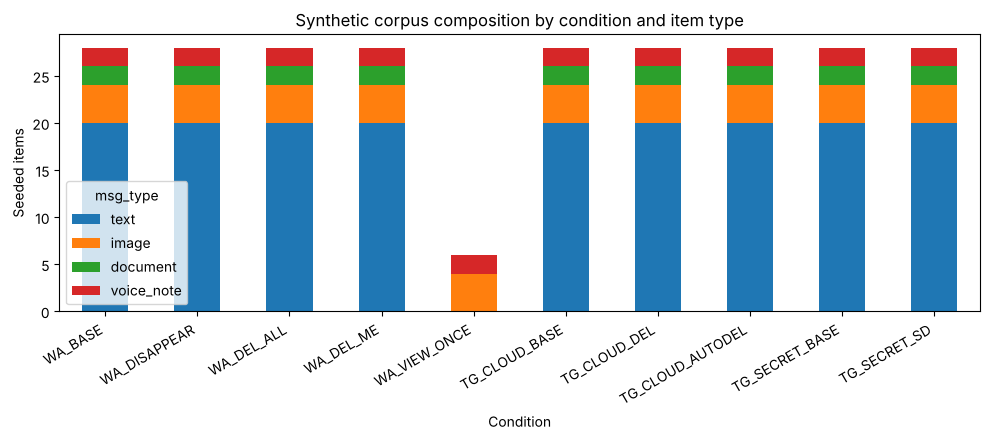

By direction:
direction   incoming  outgoing
msg_type                      
document          18         0
image             40         0
text              90        90
voice_note        20         0

Images by send mode:
send_mode
photo        18
document     18
view_once     4
Name: count, dtype: int64


msg_type,text,image,document,voice_note,total
condition_id,,,,,
WA_BASE,20,4,2,2,28
WA_DISAPPEAR,20,4,2,2,28
WA_DEL_ALL,20,4,2,2,28
WA_DEL_ME,20,4,2,2,28
WA_VIEW_ONCE,0,4,0,2,6
TG_CLOUD_BASE,20,4,2,2,28
TG_CLOUD_DEL,20,4,2,2,28
TG_CLOUD_AUTODEL,20,4,2,2,28
TG_SECRET_BASE,20,4,2,2,28


In [12]:
composition = (manifest.pivot_table(index="condition_id", columns="msg_type", values="item_id",
                                    aggfunc="count", fill_value=0)
               .reindex(conditions.condition_id)[ALL_TYPES])
composition["total"] = composition.sum(axis=1)
composition.loc["TOTAL"] = composition.sum()
composition.to_csv(os.path.join(P["outputs"], "corpus_composition.csv"))

fig, ax = plt.subplots(figsize=(10, 4.5))
composition.drop("TOTAL")[ALL_TYPES].plot(kind="bar", stacked=True, ax=ax)
ax.set_title("Synthetic corpus composition by condition and item type")
ax.set_xlabel("Condition"); ax.set_ylabel("Seeded items")
plt.xticks(rotation=30, ha="right"); plt.tight_layout()
plt.savefig(os.path.join(P["outputs"], "corpus_composition.png"), dpi=150)
plt.show()

print("By direction:"); print(manifest.groupby(["msg_type", "direction"]).size().unstack(fill_value=0))
print("\nImages by send mode:"); print(manifest[manifest.msg_type == "image"].send_mode.value_counts())
composition

## 9. Seeding run sheets

The run sheet is the step-by-step protocol followed on the phones. Fill in `actual_sent_time` and
`action_time` as you go — these become part of your chain-of-custody and experimental record.

**Seeding procedure (summarised in the run-sheet header):**
1. Before seeding, disable keyboard personalisation and clipboard history on DEV01 (otherwise typed markers
   are stored by the keyboard app and found outside WhatsApp/Telegram).
2. For each condition, open a **separate chat** between account A and account B (for secret chats, start a new
   secret chat per condition). Apply any timer setting **before** sending.
3. Send items in run-sheet order. Copy media to the peer device only.
4. Complete all T0 acquisitions.
5. Perform the post-seeding actions (deletions, opening view-once items), then wait for all timers to expire.
6. Complete all T1 acquisitions.

In [ ]:
SETUP_STEP = {
    "none":                 "Open a new 1:1 chat between A and B.",
    "enable_disappearing":  f"Open a new chat; enable Disappearing Messages ({WA_DISAPPEARING_TIMER}) BEFORE sending.",
    "delete_for_everyone":  "Open a new chat.",
    "delete_for_me":        "Open a new chat.",
    "view_once":            "Open a new chat.",
    "delete_for_both":      "Open a new chat.",
    "enable_auto_delete":   f"Open a new chat; enable Auto-Delete ({TG_AUTODELETE_TIMER}) BEFORE sending.",
    "enable_self_destruct": f"Start a NEW secret chat; set self-destruct timer ({TG_SECRET_SD_TIMER}) BEFORE sending.",
}
POST_ACTION = {
    "none":                 "No action. Leave items in place.",
    "enable_disappearing":  "No action. Wait for timer expiry before T1.",
    "delete_for_everyone":  "AFTER T0 acquisitions: select every item and choose 'Delete for everyone' on DEV01.",
    "delete_for_me":        "AFTER T0 acquisitions: select every item and choose 'Delete for me' on DEV01.",
    "view_once":            "AFTER T0 acquisitions: open each view-once item on DEV01 once.",
    "delete_for_both":      "AFTER T0 acquisitions: delete every item on DEV01, ticking 'Also delete for Test Bravo'.",
    "enable_auto_delete":   "No action. Wait for timer expiry before T1.",
    "enable_self_destruct": "Items are read on receipt; timer starts then. Ensure T0 completes before expiry.",
}

def how_to_send(r):
    who = "DEV01 (A)" if r.direction == "outgoing" else "PEER (B)"
    if r.msg_type == "text":
        return who, f"Paste/type exactly: {r.content_text}"
    if r.msg_type == "image":
        how = {"photo": "attach as PHOTO (gallery)", "document": "attach as DOCUMENT/FILE",
               "view_once": "attach as PHOTO with View Once enabled"}[r.send_mode]
        return who, f"Send {r.file_name}: {how}"
    if r.msg_type == "document":
        return who, f"Send {r.file_name} as DOCUMENT/FILE"
    vo = " with View Once enabled" if r.send_mode == "view_once_voice" else ""
    return who, f"Record voice note{vo}, reading: \"{r.content_text}\""

sheet_rows = []
for dev in DEVICES:
    for step, r in enumerate(manifest.itertuples(), 1):
        who, instr = how_to_send(r)
        sheet_rows.append({"device_id": dev["device_id"], "step": step, "condition_id": r.condition_id,
                           "item_id": r.item_id, "marker": r.marker, "send_from": who, "instruction": instr,
                           "actual_sent_time": "", "action_time": "", "notes": ""})
run_sheet = pd.DataFrame(sheet_rows)
_rs_csv = os.path.join(P["runsheets"], "seeding_run_sheet.csv")
_keep_run_sheet = FREEZE_CORPUS and os.path.exists(_rs_csv)   # never overwrite a filled-in run sheet
if not _keep_run_sheet:
    run_sheet.to_csv(_rs_csv, index=False)

# Printable markdown version, one section per condition
lines = ["# Seeding Run Sheet", "",
         "Researcher: Gerhard Uundjondjo (226111989)", "",
         "Before starting: disable keyboard personalisation and clipboard history on DEV01. "
         "Copy media files to the PEER device only.", ""]
for _, c in conditions.iterrows():
    lines += [f"## {c.condition_id} — {c.description}", "",
              f"**Setup:** {SETUP_STEP[c.af_action]}", "",
              "| # | From | Instruction | Sent time |", "|---|---|---|---|"]
    for r in run_sheet[run_sheet.condition_id == c.condition_id].itertuples():
        lines.append(f"| {r.step} | {r.send_from} | {r.instruction.replace('|', '/').replace(chr(10), ' ')} | |")
    lines += ["", f"**Post-seeding action:** {POST_ACTION[c.af_action]}", "", "Action time: ________", ""]
if not _keep_run_sheet:
    with open(os.path.join(P["runsheets"], "seeding_run_sheet.md"), "w", encoding="utf-8") as f:
        f.write("\n".join(lines))

# Voice scripts on their own for easy reading while recording
manifest[manifest.msg_type == "voice_note"][["item_id", "condition_id", "content_text"]].to_csv(
    os.path.join(P["voice"], "voice_note_scripts.csv"), index=False)

print(f"Run sheet: {len(run_sheet)} steps "
      + ("(existing files kept, not overwritten)" if _keep_run_sheet else f"written to {P['runsheets']}"))
run_sheet[["step", "condition_id", "send_from", "instruction"]].head(8)

## 10. Recovery measurement — the acquisitions actually performed

DEV01 is not rooted, so every acquisition is a **logical ADB pull** (Section 3.2.4.5). The acquisitions
below are the ones actually performed in October 2026; `REAL_ACQUISITIONS` (Section 10.2) maps each to
its folder under `03_acquisitions/`:

| Acquisition | Run | Folder | Pulled |
|---|---|---|---|
| WA_T0 / WA_T1 | WhatsApp run (19-20 Oct) | `DEV01_T0_logical_adb/wa_media`, `DEV01_T1_logical_adb/wa_media` | `/sdcard/Android/media/com.whatsapp` |
| TG2_T0 / TG2_T1 | Telegram run 2 (21-22 Oct) | `DEV01_TG2_T0_logical_adb`, `DEV01_TG2_T1_logical_adb` | `/sdcard/Android/data/org.telegram.messenger` |
| TG1_T0 / TG1_T1 | Telegram run 1 (9-20 Oct), **confounded** | `DEV01_T0_logical_adb/tg_data`, `DEV01_T1_logical_adb/tg_data` | as above |

Telegram run 1 is kept but reported separately: between its T0 and T1 the app auto-updated
(12.10.3 to 13.0.3, 17 Oct) while device storage was 99% full, and even the control items were lost, so
its T1 cannot be attributed to the anti-forensic conditions. Run 2 repeats all five Telegram conditions with
auto-update disabled and 14 GB free.

The toolkit:

1. **Scans** every file for markers in UTF-8 and UTF-16LE (streamed, so large files are fine). This also
   finds markers inside PDFs whose bytes the app changed, and in the Exif of images sent as documents.
2. **Matches images** by SHA-256 (exact copies) and dHash (recompressed photos), restricted to the
   acquisition's own platform, and records whether Exif GPS/timestamp survived.
3. **Matches documents** by SHA-256 and marker.
4. Takes **voice notes** from a manual verification file: you listen to each candidate audio file at T0
   once; T1 is then filled automatically by checking whether the identical file (same SHA-256) is still there.
5. Computes **recovery rates with 95% Wilson confidence intervals** per run, time point and condition.

Text messages were not seeded (they live only in the root-protected message databases), so they are
excluded from scoring rather than counted as losses.


### 10.0 Variables framework and comparison sources

The dependent and independent variables below follow the framework agreed for this study (see
`Variables_for_the_research.docx`). Not every dependent variable is assessable given DEV01's confirmed
non-rooted status (Section 3.2.4.5): any variable that requires reading WhatsApp's or Telegram's private
application database (`msgstore.db`, `cache4.db`) cannot be measured on this device by logical acquisition
alone, and is recorded as such rather than estimated or left silently blank.

**Independent variables**, already captured in the manifest: `platform` (Application), `chat_mode` (Chat
type: standard / cloud / secret), `af_action` (User action: none / delete / clear / self-destruct /
view-once), `msg_type` (Data type: text / image / document / voice note), `timepoint` (Time elapsed after
action: T0 vs T1). Encryption mode is implied by `chat_mode`; device model and application version are held
fixed (Table 3.5) rather than varied, since only one device is available.

**Dependent variables**, and whether DEV01 can assess them:

| Dependent variable | Assessable on DEV01? | How it is measured here |
|---|---|---|
| Media content recovered | Yes | Perceptual hash (images) or SHA-256 (documents) match against the seeded original |
| Timestamp recovered | Yes, for images | Exif `DateTimeOriginal` presence in the recovered file |
| Deleted-item trace remaining | Yes | Item still found at T1 under a condition whose `af_action` is not `none` |
| Recovery completeness (0-100%) | Yes, partial | Per image: share of {content match, Exif GPS, Exif timestamp} retained; 0/100 for document and voice-note items |
| Message content recovered (text) | **No — requires root** | `msgstore.db` / `cache4.db` are root-only paths (Section 3.2.4.5) |
| Sender / recipient recovered | **No — requires root** | Same reason; external media storage carries no sender/recipient metadata |
| Database artefact remaining | **No — requires root** | Cannot inspect `msgstore.db` / `cache4.db` contents without root |
| Cache artefact remaining | **No — requires root** | Application-private cache (`/data/data/...`) is unreachable without root |
| Network evidence remaining | **Out of scope for this device** | No packet capture is performed in this design; see the comparison source below |

**Comparison sources (discussed in Chapter 4, never merged with this study's data).** Two recent external
sources were produced on different devices and at a different unit of analysis, so their figures are cited
for comparison, not combined into the manifest:

- SowatKheang. (2026). *Telegram forensics Android case study: Residual artefacts after cloud and secret
  chat usage* [GitHub repository]. https://github.com/SowatKheang/telegram_forensics_android_case_study —
  reports, for Telegram v12 on Android 13, that deleted messages leave no in-database trace beyond
  non-contiguous row identifiers, and that secret chats leave minimal OS-level log traces.
- Jiwueze, B., Mfodwo, E., & Liu, Q. (2026). *Encrypted social media traffic fingerprinting under temporal
  shift: A public benchmark and multi-flow evaluation* [Preprint]. Preprints.org.
  https://www.preprints.org/manuscript/202609.0324 — a public benchmark of 25,116 encrypted network flows
  across ten applications including WhatsApp and Telegram, relevant to the network-evidence dependent
  variable that this device's design cannot itself assess.

Chapter 4 discusses whether this study's on-device findings are consistent with the patterns these two
sources report; their figures are never treated as additional rows of this study's own recovery data.

In [ ]:
def fs_path(p: str) -> str:
    """Absolute path; on Windows add the \\\\?\\ prefix so paths longer than 260 characters still open."""
    p = os.path.abspath(p)
    if os.name == "nt" and not p.startswith("\\\\?\\"):
        p = "\\\\?\\" + p
    return p

ARTEFACT_SOURCES = [   # (regex on lower-case path relative to the acquisition folder, category) - first match wins
    (r"inputmethod|gboard|swiftkey|clipboard",           "keyboard_or_clipboard_cache (non-app)"),
    (r"\.lime$|\.mem$|memdump|memory",                  "memory_image"),
    (r"scalpel|foremost|carved|unalloc",                 "carved_unallocated"),
    # WhatsApp: /sdcard/Android/media/com.whatsapp (no root required)
    (r"com\.whatsapp/whatsapp/\.shared",                 "whatsapp_.Shared_temp"),
    (r"com\.whatsapp/whatsapp/media/\.statuses",         "whatsapp_statuses"),
    (r"com\.whatsapp/whatsapp/media/\.links",            "whatsapp_link_previews"),
    (r"whatsapp documents",                              "whatsapp_documents_folder"),
    (r"whatsapp images",                                 "whatsapp_images_folder"),
    (r"whatsapp voice notes",                            "whatsapp_voice_notes_folder"),
    (r"whatsapp video",                                  "whatsapp_video_folder"),
    (r"whatsapp audio",                                  "whatsapp_audio_folder"),
    (r"com\.whatsapp",                                   "whatsapp_external_media_other"),
    # Telegram: /sdcard/Android/data/org.telegram.messenger (readable over ADB on this build)
    (r"org\.telegram\.messenger/cache",                  "telegram_cache (Android/data)"),
    (r"org\.telegram\.messenger/files/telegram",         "telegram_files (Android/data)"),
    (r"org\.telegram",                                   "telegram_other"),
    (r"msgstore\.db",                                    "whatsapp_message_db (requires root)"),
    (r"cache4\.db",                                      "telegram_message_db (requires root)"),
    (r"thumb",                                           "thumbnail_cache"),
    (r"\.(dd|img|raw|e01|bin)$",                         "raw_image_unattributed"),
]
EXCLUDE_PATH_PATTERNS = []   # regexes on the relative path of files to ignore entirely

def classify_source(path: str) -> str:
    p = path.replace("\\", "/").lower()
    for pattern, category in ARTEFACT_SOURCES:
        if re.search(pattern, p):
            return category
    return "other"

VALID_MARKERS = set(manifest.marker)
CHUNK = 64 * 1024 * 1024
OVERLAP = 64

def scan_file_for_markers(path: str):
    """Stream a file of any size; return hits as (marker, encoding, byte_offset)."""
    hits, seen = [], set()
    with open(path, "rb") as f:
        pos, tail = 0, b""
        while True:
            chunk = f.read(CHUNK)
            if not chunk:
                break
            buf = tail + chunk
            base = pos - len(tail)
            for enc, rx in (("utf-8", MARKER_RE_UTF8), ("utf-16le", MARKER_RE_UTF16)):
                for m in rx.finditer(buf):
                    token = m.group().decode("utf-16le" if enc == "utf-16le" else "ascii")
                    off = base + m.start()
                    if token in VALID_MARKERS and (token, enc, off) not in seen:
                        seen.add((token, enc, off)); hits.append((token, enc, off))
            tail = buf[-OVERLAP:]
            pos += len(chunk)
    return hits

def scan_acquisition(acq_dir: str) -> pd.DataFrame:
    rows = []
    root_fs = fs_path(acq_dir)
    for root, _, fnames in os.walk(root_fs):
        for fn in fnames:
            fp = os.path.join(root, fn)
            rel = os.path.relpath(fp, root_fs).replace("\\", "/")
            if any(re.search(x, rel) for x in EXCLUDE_PATH_PATTERNS):
                continue
            try:
                for token, enc, off in scan_file_for_markers(fp):
                    rows.append({"marker": token, "encoding": enc, "file": rel, "offset": off,
                                 "source": classify_source(rel), "evidence": "marker"})
            except (PermissionError, OSError) as e:
                print("  skipped", rel, e)
    return pd.DataFrame(rows, columns=["marker", "encoding", "file", "offset", "source", "evidence"])


In [ ]:
IMAGE_EXT = (".jpg", ".jpeg", ".png", ".webp")
DHASH_THRESHOLD = 10          # max Hamming distance to accept a recovered image as a match
MAX_HASH_BYTES = 200 * 1024 * 1024

manifest_images = manifest[manifest.msg_type == "image"].assign(dh=lambda d: d.dhash_hex.map(lambda h: int(h, 16)))
sha_to_marker = dict(zip(manifest.loc[manifest.sha256 != "", "sha256"], manifest.loc[manifest.sha256 != "", "marker"]))

def exif_metadata_present(path: str):
    """Returns (gps_retained, datetime_retained) for a recovered image."""
    try:
        exif = Image.open(path).getexif()
        return bool(exif.get_ifd(0x8825)), bool(exif.get(0x0132))
    except Exception:
        return False, False

def match_files(acq_dir: str, platform: str = None) -> pd.DataFrame:
    """Exact (SHA-256) matches for images/documents, perceptual (dHash) matches for images.
    `platform` restricts candidate references to that app's items (avoids cross-platform look-alikes)."""
    ref_imgs = manifest_images if platform is None else manifest_images[manifest_images.platform == platform]
    ref_sha = sha_to_marker if platform is None else {
        h: m for h, m in sha_to_marker.items() if (platform == "WhatsApp") == m.startswith("AFXW")}
    rows = []
    root_fs = fs_path(acq_dir)
    for root, _, fnames in os.walk(root_fs):
        for fn in fnames:
            fp = os.path.join(root, fn)
            rel = os.path.relpath(fp, root_fs).replace("\\", "/")
            if any(re.search(x, rel) for x in EXCLUDE_PATH_PATTERNS):
                continue
            try:
                size = os.path.getsize(fp)
            except OSError:
                continue
            if size <= MAX_HASH_BYTES:
                try:
                    h = sha256_file(fp)
                except OSError:
                    continue
                if h in ref_sha:
                    gps, dt = exif_metadata_present(fp)
                    rows.append({"marker": ref_sha[h], "encoding": "", "file": rel, "offset": 0,
                                 "source": classify_source(rel), "evidence": "sha256_exact",
                                 "dhash_distance": 0, "exif_gps_retained": gps, "exif_datetime_retained": dt})
                    continue
            if fn.lower().endswith(IMAGE_EXT) and len(ref_imgs):
                try:
                    d = dhash(Image.open(fp))
                except Exception:
                    continue
                dists = ref_imgs.dh.map(lambda x: hamming(x, d))
                best = dists.idxmin()
                if dists[best] <= DHASH_THRESHOLD:
                    gps, dt = exif_metadata_present(fp)
                    rows.append({"marker": ref_imgs.at[best, "marker"], "encoding": "", "file": rel,
                                 "offset": 0, "source": classify_source(rel), "evidence": "dhash_perceptual",
                                 "dhash_distance": int(dists[best]), "exif_gps_retained": gps,
                                 "exif_datetime_retained": dt})
    return pd.DataFrame(rows, columns=["marker", "encoding", "file", "offset", "source", "evidence",
                                       "dhash_distance", "exif_gps_retained", "exif_datetime_retained"])


In [ ]:
NOT_ASSESSABLE_MSG = "Not assessable on DEV01 (requires root; see Section 3.2.4.5)"


def wilson_ci(k: int, n: int, z: float = 1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * math.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return (max(0.0, centre - half), min(1.0, centre + half))


# ---------------------------------------------------------------------------------------------
# 10.2  The acquisitions actually performed (logical ADB pulls, October 2026)
# ---------------------------------------------------------------------------------------------
REAL_ACQUISITIONS = pd.DataFrame([
    # acquisition_id, run,                 platform,   tp,   folder under 03_acquisitions,        pulled (local time),  SHA-256 list
    ("WA_T0",  "WA_run",             "WhatsApp", "T0", "DEV01_T0_logical_adb/wa_media",     "2026-10-19 15:44", "DEV01_T0_sha256.csv"),
    ("WA_T1",  "WA_run",             "WhatsApp", "T1", "DEV01_T1_logical_adb/wa_media",     "2026-10-20 16:09", "DEV01_T1_sha256.csv"),
    ("TG2_T0", "TG_run2",            "Telegram", "T0", "DEV01_TG2_T0_logical_adb",          "2026-10-21 12:49", "DEV01_TG2_T0_sha256.csv"),
    ("TG2_T1", "TG_run2",            "Telegram", "T1", "DEV01_TG2_T1_logical_adb",          "2026-10-22 14:26", "DEV01_TG2_T1_sha256.csv"),
    ("TG1_T0", "TG_run1_confounded", "Telegram", "T0", "DEV01_T0_logical_adb/tg_data",      "2026-10-09 16:39", "DEV01_T0_sha256.csv"),
    ("TG1_T1", "TG_run1_confounded", "Telegram", "T1", "DEV01_T1_logical_adb/tg_data",      "2026-10-20 16:20", "DEV01_T1_sha256.csv"),
], columns=["acquisition_id", "run", "platform", "timepoint", "folder", "pulled_at", "sha256_list"])
REAL_ACQUISITIONS["modality"] = "logical_adb"
PRIMARY_RUNS = ["WA_run", "TG_run2"]            # the runs reported as the main results
SCORED_TYPES = ["image", "document", "voice_note"]   # text was not seeded (database-only; requires root)
REAL_ACQUISITIONS.to_csv(os.path.join(P["design"], "acquisitions_performed.csv"), index=False)

# Protocol deviations that would otherwise distort a condition's result (recorded in Chapter 3).
# (acquisition_id regex, marker, regex on the hit's relative file path, reason)
EXCLUDE_HITS = [
    (r"^WA_", "AFXW0021TG3", r"whatsapp documents", "WA_BASE photo item also sent a second time as a document (deviation)"),
    (r"^WA_", "AFXW0023GCI", r"whatsapp documents", "WA_BASE photo item also sent a second time as a document (deviation)"),
]

# Items that were never sent in their designed form: removed from that run's denominators (not counted as losses).
# Decide these from the photo audit (Section 10.5) and record the evidence.
NOT_SEEDED = {
    # (run, marker): reason
    ("WA_run", "AFXW0021TG3"): "WA_BASE_021 photo: only document copies were received; no photo copy dated 19 Oct "
                               "(IMG-20261019-WA0003/0004 checked visually: chat screenshots, not test images)",
    ("WA_run", "AFXW0023GCI"): "WA_BASE_023 photo: only document copies were received; photo audit shows no "
                               "19 Oct image within 20 bits of it",
}

# Visual checks of borderline or look-alike image matches (marker printed on every test image).
VISUAL_CHECKS = pd.DataFrame([
    ("WA_T1", "IMG-20240609-WA... (WhatsApp Images)", "matched WA_DISAPPEAR_021 by dHash",
     "NOT a test image (2024 football photo): false positive, excluded by the seeding-date rule"),
    ("WA_T0", "WhatsApp Images/Private/IMG-20261019-WA0003.jpg", "closest AFXW0021TG3 at 21 bits",
     "chat screenshot, not a test image"),
    ("WA_T0", "WhatsApp Images/Private/IMG-20261019-WA0004.jpg", "closest AFXW005262Q at 27 bits",
     "chat screenshot, not a test image"),
    ("TG2_T1", "tg_data/.../cache/-5962945672494718... and -5965197472308403... (4 files)",
     "matched TG_CLOUD_DEL_022/024 and TG_CLOUD_AUTODEL_022/024 by dHash",
     "test block-pattern images with marker strip: genuine residual cached previews"),
], columns=["acquisition_id", "file", "automatic_result", "visual_finding"])
VISUAL_CHECKS.to_csv(os.path.join(P["analysis"], "visual_checks.csv"), index=False)

def acq_dir_of(row) -> str:
    return os.path.join(P["acquisitions"], *row.folder.split("/"))

# ---------------------------------------------------------------------------------------------
# 10.3  Voice notes: candidates to listen to, verification file, automatic T1 fill
# ---------------------------------------------------------------------------------------------
AUDIO_EXT = (".opus", ".ogg", ".m4a", ".aac", ".mp3", ".amr", ".wav")
WA_SEED_DATE_TAG = "-20261019-"     # WhatsApp names received media by date; the re-seed was on 19 Oct
VOICE_VERIFY_FILE = os.path.join(P["analysis"], "voice_note_verification.csv")
VOICE_CANDIDATES_FILE = os.path.join(P["analysis"], "voice_note_candidates.csv")
_VV_COLS = ["acquisition_id", "run", "timepoint", "item_id", "marker", "condition_id", "file", "recovered", "notes"]

def list_voice_candidates():
    rows = []
    for a in REAL_ACQUISITIONS.itertuples():
        d = acq_dir_of(a)
        if not os.path.isdir(d):
            continue
        root_fs = fs_path(d)
        for root, _, fnames in os.walk(root_fs):
            for fn in fnames:
                if not fn.lower().endswith(AUDIO_EXT):
                    continue
                if a.platform == "WhatsApp" and WA_SEED_DATE_TAG not in fn:
                    continue
                fp = os.path.join(root, fn)
                rel = os.path.relpath(fp, root_fs).replace("\\", "/")
                rows.append({"acquisition_id": a.acquisition_id, "run": a.run, "file": rel,
                             "size_bytes": os.path.getsize(fp), "sha256": sha256_file(fp),
                             "full_path": os.path.join(d, *rel.split("/"))})
    cand = pd.DataFrame(rows, columns=["acquisition_id", "run", "file", "size_bytes", "sha256", "full_path"])
    cand.to_csv(VOICE_CANDIDATES_FILE, index=False)
    return cand

def _voice_template():
    vt = manifest[manifest.msg_type == "voice_note"][["item_id", "marker", "condition_id", "platform"]]
    parts = []
    for a in REAL_ACQUISITIONS.itertuples():
        sub = vt[vt.platform == a.platform].drop(columns="platform")
        parts.append(sub.assign(acquisition_id=a.acquisition_id, run=a.run, timepoint=a.timepoint,
                                file="", recovered="", notes=""))
    return pd.concat(parts)[_VV_COLS]

def load_voice_verification():
    if os.path.exists(VOICE_VERIFY_FILE):
        vv = pd.read_csv(VOICE_VERIFY_FILE, dtype=str, keep_default_na=False)
        if set(_VV_COLS) <= set(vv.columns) and set(vv.acquisition_id) & set(REAL_ACQUISITIONS.acquisition_id):
            return vv
        backup = VOICE_VERIFY_FILE.replace(".csv", "_old_format.csv")
        os.replace(VOICE_VERIFY_FILE, backup)
        print("Older voice-verification file kept as", backup)
    vv = _voice_template()
    vv.to_csv(VOICE_VERIFY_FILE, index=False)
    print("Voice-note verification file written:", VOICE_VERIFY_FILE)
    return vv.astype(str)

def prefill_voice_t1():
    """For every T0 row you marked recovered=1 with its file, fill the matching T1 row automatically:
    1 if the identical file (same relative path AND same SHA-256) is still present at T1, else 0."""
    vv = load_voice_verification()
    filled = 0
    for run in vv.run.unique():
        acq = REAL_ACQUISITIONS[REAL_ACQUISITIONS.run == run].set_index("timepoint")
        if not {"T0", "T1"} <= set(acq.index):
            continue
        d0, d1 = acq_dir_of(acq.loc["T0"]), acq_dir_of(acq.loc["T1"])
        t0 = vv[(vv.run == run) & (vv.timepoint == "T0") & (vv.recovered.isin(["1", "1.0"])) & (vv.file != "")]
        for r in t0.itertuples():
            mask = (vv.run == run) & (vv.timepoint == "T1") & (vv.item_id == r.item_id) & (vv.recovered == "")
            if not mask.any():
                continue
            f0 = os.path.join(d0, *r.file.split("/"))
            f1 = os.path.join(d1, *r.file.split("/"))
            present = os.path.exists(fs_path(f1)) and sha256_file(fs_path(f1)) == sha256_file(fs_path(f0))
            vv.loc[mask, ["file", "recovered", "notes"]] = [r.file, "1" if present else "0",
                "auto: identical file present at T1" if present else "auto: file absent or changed at T1"]
            filled += int(mask.sum())
        # items you found NOT present at T0 cannot reappear at T1
        t0_absent = vv[(vv.run == run) & (vv.timepoint == "T0") & (vv.recovered.isin(["0", "0.0"]))]
        for r in t0_absent.itertuples():
            mask = (vv.run == run) & (vv.timepoint == "T1") & (vv.item_id == r.item_id) & (vv.recovered == "")
            vv.loc[mask, ["recovered", "notes"]] = ["0", "auto: not present at T0"]
            filled += int(mask.sum())
    vv.to_csv(VOICE_VERIFY_FILE, index=False)
    return filled

# ---------------------------------------------------------------------------------------------
# 10.4  Scoring
# ---------------------------------------------------------------------------------------------
def _apply_exclusions(hits: pd.DataFrame):
    if hits.empty or not EXCLUDE_HITS:
        return hits, hits.iloc[0:0]
    drop = pd.Series(False, index=hits.index)
    reasons = pd.Series("", index=hits.index)
    for acq_rx, marker, file_rx, reason in EXCLUDE_HITS:
        m = (hits.acquisition_id.str.contains(acq_rx) & (hits.marker == marker)
             & hits.file.str.lower().str.contains(file_rx))
        drop |= m
        reasons[m] = reason
    return hits[~drop].copy(), hits[drop].assign(exclusion_reason=reasons[drop])

def score_all_acquisitions():
    """Scan every performed acquisition; return (evidence_hits, item_level_recovery, excluded_hits)."""
    all_hits, scanned_ids = [], []
    for a in REAL_ACQUISITIONS.itertuples():
        d = acq_dir_of(a)
        if not os.path.isdir(d) or not any(os.scandir(d)):
            print(f"  {a.acquisition_id}: folder not found or empty ({d}) - skipped")
            continue
        print(f"Scanning {a.acquisition_id} ({a.run}, {a.timepoint}) ...")
        h = pd.concat([scan_acquisition(d), match_files(d, a.platform)], ignore_index=True)
        h["acquisition_id"] = a.acquisition_id
        all_hits.append(h)
        scanned_ids.append(a.acquisition_id)
    if not all_hits:
        return None, None, None
    hits = pd.concat(all_hits, ignore_index=True)
    plat = dict(zip(manifest.marker, manifest.platform))
    acq_plat = dict(zip(REAL_ACQUISITIONS.acquisition_id, REAL_ACQUISITIONS.platform))
    hits = hits[hits.marker.map(plat) == hits.acquisition_id.map(acq_plat)]   # same-platform evidence only
    # WhatsApp names received media by date and every test photo arrived on the seeding day, so a
    # perceptual (look-alike) match on a WhatsApp file NOT dated that day comes from the researcher's
    # own history: a false positive (confirmed visually for IMG-20240609-WA..., Oct 2026).
    wa_lookalike = (hits.acquisition_id.isin(REAL_ACQUISITIONS.loc[REAL_ACQUISITIONS.platform == "WhatsApp",
                                                                   "acquisition_id"])
                    & (hits.evidence == "dhash_perceptual")
                    & ~hits.file.str.contains(WA_SEED_DATE_TAG, regex=False)
                    # a document-mode copy keeps its original name (the marker), so it is not a look-alike
                    & ~pd.Series([m in f for m, f in zip(hits.marker, hits.file)], index=hits.index))
    lookalikes = hits[wa_lookalike].assign(
        exclusion_reason="look-alike: dHash match on a WhatsApp file not dated on the seeding day (false positive)")
    hits = hits[~wa_lookalike]
    hits, excluded = _apply_exclusions(hits)
    excluded = pd.concat([lookalikes, excluded], ignore_index=True)

    scanned = REAL_ACQUISITIONS[REAL_ACQUISITIONS.acquisition_id.isin(scanned_ids)]
    items = manifest[manifest.msg_type.isin(SCORED_TYPES)][[
        "item_id", "marker", "condition_id", "platform", "af_mechanism", "msg_type",
        "send_mode", "direction", "match_method"]]
    grid = scanned[["acquisition_id", "run", "platform", "timepoint", "modality"]].merge(items, on="platform")
    for (run_, marker_), why in NOT_SEEDED.items():          # seeding deviations: item never sent as designed
        grid = grid[~((grid.run == run_) & (grid.marker == marker_))]

    found = hits.groupby(["acquisition_id", "marker"]).agg(
        n_hits=("file", "size"),
        evidence_types=("evidence", lambda s: ";".join(sorted(set(s)))),
        sources=("source", lambda s: ";".join(sorted(set(s)))),
        files=("file", lambda s: ";".join(sorted(set(s))[:5])),
        exif_gps_retained=("exif_gps_retained", lambda s: bool(pd.Series(s).fillna(False).astype(bool).any())),
        exif_datetime_retained=("exif_datetime_retained",
                                lambda s: bool(pd.Series(s).fillna(False).astype(bool).any())),
    ).reset_index()
    item = grid.merge(found, on=["acquisition_id", "marker"], how="left")
    item["recovered"] = item.n_hits.notna().astype(float)
    for col in ("exif_gps_retained", "exif_datetime_retained"):
        item[col] = item[col].fillna(False).astype(bool)

    # voice notes: manual verification (T0 by listening, T1 auto-filled) overrides automatic scanning
    vv = load_voice_verification()
    vv = vv[vv.recovered.isin(["0", "1", "0.0", "1.0"])]
    vmap = {(r.acquisition_id, r.item_id): float(r.recovered) for r in vv.itertuples()}
    mask = item.msg_type == "voice_note"
    item.loc[mask, "recovered"] = [vmap.get((a, i), np.nan) for a, i in
                                   zip(item.loc[mask, "acquisition_id"], item.loc[mask, "item_id"])]
    fmap = {(r.acquisition_id, r.item_id): r.file for r in vv.itertuples() if str(r.recovered) in ("1", "1.0")}
    item.loc[mask, "files"] = [fmap.get((a, i), np.nan) for a, i in
                               zip(item.loc[mask, "acquisition_id"], item.loc[mask, "item_id"])]

    # --- DV/IV annotation per the Variables_for_the_research.docx framework (Section 10.0) ---
    cond_action = dict(zip(conditions.condition_id, conditions.af_action))
    item["af_action"] = item.condition_id.map(cond_action)
    deleted_relevant = item.af_action != "none"
    item["deleted_message_trace"] = np.where((item.timepoint == "T1") & deleted_relevant, item.recovered, np.nan)
    item["timestamp_recovered"] = np.where(item.msg_type == "image", item.exif_datetime_retained.astype(float), np.nan)
    item["message_content_recovered"] = NOT_ASSESSABLE_MSG
    item["sender_recovered"] = NOT_ASSESSABLE_MSG
    item["recipient_recovered"] = NOT_ASSESSABLE_MSG
    item["database_artifact_remaining"] = NOT_ASSESSABLE_MSG
    item["cache_artifact_remaining"] = np.where(
        item.sources.fillna("").str.contains("cache|thumb|shared")
        | item.files.fillna("").str.lower().str.contains("/cache/|/.shared/"), 1.0, np.where(item.recovered.notna(), 0.0, np.nan))
    item["network_evidence_remaining"] = "Out of scope for this device; see Jiwueze et al. (2026)"

    def _completeness(r):
        if pd.isna(r.recovered):
            return np.nan
        if r.msg_type != "image":
            return 100.0 if r.recovered == 1 else 0.0
        if r.recovered == 0:
            return 0.0
        parts = [1.0, float(r.exif_gps_retained), float(r.exif_datetime_retained)]
        return 100.0 * sum(parts) / len(parts)

    item["recovery_completeness_pct"] = item.apply(_completeness, axis=1)
    return hits, item, excluded

def recovery_table(item: pd.DataFrame, by):
    d = item.dropna(subset=["recovered"])
    g = d.groupby(by).recovered.agg(recovered="sum", n="count").reset_index()
    g["recovered"] = g.recovered.astype(int)
    g["recovery_rate"] = g.recovered / g.n
    ci = g.apply(lambda r: wilson_ci(int(r.recovered), int(r.n)), axis=1)
    g["ci95_low"] = [c[0] for c in ci]; g["ci95_high"] = [c[1] for c in ci]
    return g


In [ ]:
n_auto = prefill_voice_t1()
if n_auto:
    print(f"Voice notes: {n_auto} T1 row(s) filled automatically from T0 verification.\n")
voice_cand = list_voice_candidates()

hits, item_recovery, excluded_hits = score_all_acquisitions()

if hits is None:
    print("No acquisition folders found. Check REAL_ACQUISITIONS (Section 10.2) against "
          f"the folders under {P['acquisitions']}.")
else:
    hits.to_csv(os.path.join(P["analysis"], "evidence_hits.csv"), index=False)
    excluded_hits.to_csv(os.path.join(P["analysis"], "evidence_hits_excluded_deviations.csv"), index=False)
    item_recovery.to_csv(os.path.join(P["analysis"], "item_level_recovery.csv"), index=False)

    # 1. Recovery by run, time point and condition (95% Wilson CIs)
    by_cond = recovery_table(item_recovery, ["run", "timepoint", "condition_id"])
    by_cond.to_csv(os.path.join(P["outputs"], "recovery_by_condition_timepoint.csv"), index=False)

    # 2. T0 vs T1 per condition: the core Chapter 4 table
    order = list(conditions.condition_id)
    w = by_cond.pivot_table(index=["run", "condition_id"], columns="timepoint",
                            values=["recovered", "n"], aggfunc="first")
    w.columns = [f"{a}_{b}" for a, b in w.columns]
    w = w.reset_index()
    for tp in ("T0", "T1"):
        if f"recovered_{tp}" not in w:
            w[f"recovered_{tp}"] = np.nan; w[f"n_{tp}"] = np.nan
    w["T0"] = w.apply(lambda r: f"{int(r.recovered_T0)}/{int(r.n_T0)}" if pd.notna(r.recovered_T0) else "", axis=1)
    w["T1"] = w.apply(lambda r: f"{int(r.recovered_T1)}/{int(r.n_T1)}" if pd.notna(r.recovered_T1) else "", axis=1)
    w["retained_T1_of_T0"] = w.apply(
        lambda r: f"{r.recovered_T1 / r.recovered_T0:.0%}" if pd.notna(r.recovered_T1) and r.recovered_T0 else "", axis=1)
    mech = dict(zip(conditions.condition_id, conditions.af_mechanism))
    w["mechanism"] = w.condition_id.map(mech)
    w["_o"] = w.condition_id.map({c: k for k, c in enumerate(order)})
    t0_t1 = w.sort_values(["run", "_o"])[["run", "condition_id", "mechanism", "T0", "T1", "retained_T1_of_T0"]]
    t0_t1.to_csv(os.path.join(P["outputs"], "t0_vs_t1_by_condition.csv"), index=False)

    # 3. By item type and send mode
    by_type = recovery_table(item_recovery, ["run", "timepoint", "platform", "msg_type", "send_mode"])
    by_type.to_csv(os.path.join(P["outputs"], "recovery_by_type_sendmode.csv"), index=False)

    # 4. Where the evidence was found (artefact source)
    by_source = (hits.merge(manifest[["marker", "condition_id"]], on="marker")
                     .groupby(["acquisition_id", "source"]).marker.nunique().rename("distinct_items").reset_index())
    by_source.to_csv(os.path.join(P["outputs"], "recovery_by_artefact_source.csv"), index=False)

    # 5. Exif survival by platform and send mode (recovered images only)
    img = item_recovery[(item_recovery.msg_type == "image") & (item_recovery.recovered == 1)]
    if len(img):
        exif_tbl = (img.groupby(["run", "timepoint", "platform", "send_mode"])
                       .agg(recovered_images=("item_id", "count"),
                            gps_retained=("exif_gps_retained", "sum"),
                            datetime_retained=("exif_datetime_retained", "sum")))
        exif_tbl.to_csv(os.path.join(P["outputs"], "exif_retention.csv"))
        print("Exif retained in recovered images:\n", exif_tbl, "\n")

    # 6. DV summary (primary runs)
    prim = item_recovery[item_recovery.run.isin(PRIMARY_RUNS)]
    def _pct(series):
        s = pd.to_numeric(series, errors="coerce").dropna()
        return f"{s.mean():.1%} (n={len(s)})" if len(s) else "n/a"
    dv_rows = [
        ("Media content recovered", "Yes", _pct(prim.recovered)),
        ("Timestamp recovered (images)", "Yes", _pct(prim.loc[prim.msg_type == "image", "timestamp_recovered"])),
        ("Deleted-item trace remaining (T1, non-control)", "Yes", _pct(prim.deleted_message_trace)),
        ("Cache/temporary-file artefact among recovered items", "Partly",
         _pct(prim.loc[prim.recovered == 1, "cache_artifact_remaining"])),
        ("Recovery completeness (0-100%)", "Yes",
         f"mean {prim.recovery_completeness_pct.mean():.1f}%" if prim.recovery_completeness_pct.notna().any() else "n/a"),
        ("Message content recovered (text)", "No", NOT_ASSESSABLE_MSG),
        ("Sender recovered", "No", NOT_ASSESSABLE_MSG),
        ("Recipient recovered", "No", NOT_ASSESSABLE_MSG),
        ("Database artefact remaining", "No", NOT_ASSESSABLE_MSG),
        ("Network evidence remaining", "No", "Out of scope for this device; see Jiwueze et al. (2026)"),
    ]
    dv_summary = pd.DataFrame(dv_rows, columns=["dependent_variable", "assessable_on_DEV01", "summary_primary_runs"])
    dv_summary.to_csv(os.path.join(P["outputs"], "dv_variable_summary.csv"), index=False)
    print(dv_summary.to_string(index=False), "\n")

    # 7. Heatmap: conditions x (run, time point), primary runs only
    hp = by_cond[by_cond.run.isin(PRIMARY_RUNS)].copy()
    if len(hp):
        hp["col"] = hp.timepoint
        heat = hp.pivot_table(index="condition_id", columns="col", values="recovery_rate").reindex(
            [c for c in order if c in set(hp.condition_id)])
        lab = hp.pivot_table(index="condition_id", columns="col",
                             values="recovered", aggfunc="first").reindex(heat.index)
        nn = hp.pivot_table(index="condition_id", columns="col", values="n", aggfunc="first").reindex(heat.index)
        fig, ax = plt.subplots(figsize=(6, 5.5))
        im = ax.imshow(heat.values.astype(float), vmin=0, vmax=1, cmap="viridis", aspect="auto")
        ax.set_xticks(range(len(heat.columns))); ax.set_xticklabels(heat.columns)
        ax.set_yticks(range(len(heat.index))); ax.set_yticklabels(heat.index)
        for r_ in range(heat.shape[0]):
            for c_ in range(heat.shape[1]):
                v = heat.values[r_, c_]
                if not pd.isna(v):
                    ax.text(c_, r_, f"{v:.0%}\n({int(lab.values[r_, c_])}/{int(nn.values[r_, c_])})",
                            ha="center", va="center", color="white" if v < 0.6 else "black", fontsize=8)
        ax.set_title("Recovery rate by condition: T0 vs T1\n(logical ADB, WhatsApp run and Telegram run 2)")
        fig.colorbar(im, ax=ax, label="Recovery rate")
        plt.tight_layout()
        plt.savefig(os.path.join(P["outputs"], "recovery_heatmap_T0_T1.png"), dpi=150)
        plt.show()

    # Photo audit: every WhatsApp image dated on the seeding day, with its closest test image
    audit_rows = []
    for a_ in REAL_ACQUISITIONS[REAL_ACQUISITIONS.platform == "WhatsApp"].itertuples():
        d_ = acq_dir_of(a_)
        if not os.path.isdir(d_):
            continue
        root_fs = fs_path(d_)
        ref = manifest_images[manifest_images.platform == "WhatsApp"]
        for root, _, fnames in os.walk(root_fs):
            for fn in fnames:
                if WA_SEED_DATE_TAG in fn and fn.lower().endswith(IMAGE_EXT):
                    fp = os.path.join(root, fn)
                    try:
                        dh_ = dhash(Image.open(fp))
                    except Exception:
                        continue
                    dist = ref.dh.map(lambda x: hamming(x, dh_)).sort_values()
                    i0 = dist.index[0]
                    audit_rows.append({"acquisition_id": a_.acquisition_id,
                                       "file": os.path.relpath(fp, root_fs).replace("\\", "/"),
                                       "closest_marker": ref.at[i0, "marker"],
                                       "closest_item": ref.at[i0, "item_id"], "distance_bits": int(dist.iloc[0]),
                                       "matched": int(dist.iloc[0]) <= DHASH_THRESHOLD})
    photo_audit = pd.DataFrame(audit_rows)
    photo_audit.to_csv(os.path.join(P["analysis"], "photo_match_audit.csv"), index=False)
    print("\nPhoto audit (WhatsApp images dated on the seeding day):")
    print(photo_audit.to_string(index=False) if len(photo_audit) else "  none found")

    # Voice-note status
    v = item_recovery[item_recovery.msg_type == "voice_note"]
    n_unv = int(v.recovered.isna().sum())
    if n_unv:
        print(f"\n{n_unv} voice-note row(s) not yet verified (excluded from rates). Listen to the T0 files in\n"
              f"  {VOICE_CANDIDATES_FILE}\nand record item_id/file/recovered=1 in\n  {VOICE_VERIFY_FILE}\n"
              "for the T0 rows, then re-run this cell: the T1 rows are filled automatically.")
    if len(excluded_hits):
        print(f"\n{len(excluded_hits)} hit(s) excluded (protocol deviations and look-alike false positives); "
              "see evidence_hits_excluded_deviations.csv:")
        print(excluded_hits.groupby(["acquisition_id", "exclusion_reason"]).size().to_string())
    if NOT_SEEDED:
        print("\nItems removed from denominators (not seeded as designed):")
        for k, v in NOT_SEEDED.items():
            print("  ", k, "-", v)
    display(t0_t1)


## 11. Pipeline self-test (tool validation — **not** experimental results)

Before trusting the toolkit on real acquisitions, it is validated against inputs whose answer is known:

* marker text written in **UTF-8** and **UTF-16LE**, and markers placed across a **chunk boundary**, must all
  be found;
* images **recompressed, resized and stripped of EXIF** (imitating what a messaging app does to a photo) must
  still be matched to the right original by perceptual hash, and reported as having lost GPS;
* exact copies of documents must match by SHA-256;
* random bytes must produce **no** false positives.

This is reportable in Section 3.2.7 as validation of the measurement instrument. It says nothing about how
WhatsApp or Telegram behave; those findings come only from Section 10.

In [18]:
selftest_dir = os.path.join(BASE_DIR, "_selftest_tmp")
shutil.rmtree(selftest_dir, ignore_errors=True)
os.makedirs(selftest_dir)

texts = manifest[manifest.msg_type == "text"]
half = len(texts) // 2
utf8_set, utf16_set = set(texts.marker[:half]), set(texts.marker[half:])
with open(os.path.join(selftest_dir, "dump_utf8.txt"), "w", encoding="utf-8") as f:
    f.write("\n".join(texts.content_text[:half]))
with open(os.path.join(selftest_dir, "dump_utf16.bin"), "wb") as f:
    f.write("\n".join(texts.content_text[half:]).encode("utf-16le"))

# boundary test: marker straddling a chunk edge (temporarily shrink CHUNK)
boundary_marker = texts.marker.iloc[0]
_saved_chunk = CHUNK
CHUNK = 1024
with open(os.path.join(selftest_dir, "boundary.bin"), "wb") as f:
    f.write(os.urandom(1024 - 5) + boundary_marker.encode() + os.urandom(2000))
boundary_hits = scan_file_for_markers(os.path.join(selftest_dir, "boundary.bin"))
CHUNK = _saved_chunk

# false-positive test
with open(os.path.join(selftest_dir, "noise.bin"), "wb") as f:
    f.write(os.urandom(8 * 1024 * 1024))

# image test: imitate app photo processing (resize, recompress q=40, strip EXIF)
imgs = manifest[manifest.msg_type == "image"]
for r in imgs.itertuples():
    im = Image.open(os.path.join(P["images"], r.file_name)).convert("RGB")
    im.resize((800, 600), Image.LANCZOS).save(os.path.join(selftest_dir, f"IMG-recompressed-{r.item_id}.jpg"),
                                             "JPEG", quality=40)
docs = manifest[manifest.msg_type == "document"]
for r in docs.itertuples():
    shutil.copy(os.path.join(P["documents"], r.file_name), os.path.join(selftest_dir, f"copy_{r.file_name}"))

marker_hits = scan_acquisition(selftest_dir)
file_hits = match_files(selftest_dir)

found_utf8 = set(marker_hits[marker_hits.encoding == "utf-8"].marker)
found_utf16 = set(marker_hits[marker_hits.encoding == "utf-16le"].marker)
noise_hits = marker_hits[marker_hits.file == "noise.bin"]
img_match = file_hits[file_hits.evidence == "dhash_perceptual"].copy()
img_match["expected"] = img_match.file.str.extract(r"IMG-recompressed-(.+)\.jpg")[0].map(
    dict(zip(imgs.item_id, imgs.marker)))
doc_match = file_hits[file_hits.evidence == "sha256_exact"]

results = pd.DataFrame([
    ("UTF-8 text markers found", f"{len(utf8_set & found_utf8)}/{len(utf8_set)}", utf8_set <= found_utf8),
    ("UTF-16LE text markers found", f"{len(utf16_set & found_utf16)}/{len(utf16_set)}", utf16_set <= found_utf16),
    ("Marker across chunk boundary found", str(len(boundary_hits)), any(h[0] == boundary_marker for h in boundary_hits)),
    ("False positives in 8 MiB random data", str(len(noise_hits)), len(noise_hits) == 0),
    ("Recompressed images matched to correct original",
     f"{(img_match.marker == img_match.expected).sum()}/{len(imgs)}",
     (img_match.marker == img_match.expected).sum() == len(imgs)),
    ("Max dHash distance after recompression", str(img_match.dhash_distance.max()),
     img_match.dhash_distance.max() <= DHASH_THRESHOLD),
    ("Stripped images reported without GPS", f"{(~img_match.exif_gps_retained).sum()}/{len(img_match)}",
     (~img_match.exif_gps_retained).all()),
    ("Stripped images reported without Exif timestamp",
     f"{(~img_match.exif_datetime_retained).sum()}/{len(img_match)}",
     (~img_match.exif_datetime_retained).all()),
    ("Document copies matched by SHA-256", f"{len(doc_match)}/{len(docs)}", len(doc_match) == len(docs)),
], columns=["check", "result", "passed"])
results.to_csv(os.path.join(P["outputs"], "pipeline_selftest.csv"), index=False)
shutil.rmtree(selftest_dir, ignore_errors=True)
assert results.passed.all(), "Self-test failed — do not use the toolkit until fixed"
print("All self-test checks passed.")
results

All self-test checks passed.


,check,result,passed
0,UTF-8 text markers found,90/90,True
1,UTF-16LE text markers found,90/90,True
2,Marker across chunk boundary found,1,True
3,False positives in 8 MiB random data,0,True
4,Recompressed images matched to correct original,40/40,True
5,Max dHash distance after recompression,4,True
6,Stripped images reported without GPS,40/40,True
7,Stripped images reported without Exif timestamp,40/40,True
8,Document copies matched by SHA-256,18/18,True


## 12. What was replaced from the template and next steps

**Kept from the SAS821S template:** the project-folder setup, seeded synthetic data generation, data
dictionary, provenance/cleaning log, quality checks, descriptive charts and saved CSV/PNG outputs.

**Replaced:** the three SOC data sources (auth logs, network logs, tickets) are replaced by the thesis's
experimental corpus (text, images, documents, voice notes) across ten anti-forensic conditions, plus a
ground-truth manifest and seeding protocol.

**Removed as outside the thesis methodology:** supervised/unsupervised ML models, Monte Carlo control
simulation, TF-IDF text classification, predictive risk scoring, adversarial testing, the analyst dashboard
and the FastAPI deployment scaffold. The thesis is a quantitative *experimental* study measuring recovery
rates, so its analysis is the recovery measurement in Section 10.

**Next steps**
1. Print `02_corpus/run_sheets/seeding_run_sheet.md` and seed DEV01 (Samsung SM-A245F, Android 16) following it.
2. Perform T0 acquisitions: `adb pull` the externally-writable media folders, then attempt
   `adb backup -f whatsapp.ab com.whatsapp` and the Telegram equivalent (both are expected to fail on
   current Android with a non-debuggable app — record whatever `adb` actually returns either way).
3. Apply post-seeding actions; wait for all timers to expire; repeat the same acquisition for T1.
4. Place each acquisition's output in `03_acquisitions/DEV01_T0_logical_adb/` and
   `03_acquisitions/DEV01_T1_logical_adb/`, fill in the voice-note verification sheet, and re-run Section 10.
5. Report `corpus_composition.csv` in Section 3.2.4 and the Section 10 outputs in Chapter 4. If root access
   becomes available later (e.g. via Magisk), uncomment the remaining modalities in Section 0.1 and re-run.